In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import os, json, glob
import sys
import tensorflow as tf
import seaborn as sns
import matplotlib 
import matplotlib.pyplot as plt

2026-11-23 14:36:54.409680: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-23 14:36:54.428760: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795469814.445275   22490 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795469814.451178   22490 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-23 14:36:54.471304: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
from utils.hm_pyfunctions import *

In [5]:
# get config information
utils_dir = '../utils/'

with open(os.path.join(utils_dir, "param_info.json"), "r") as f:
    param_info = json.load(f)
universal_param_names = param_info['u_params']
pft_param_names = param_info['pft_params']

la = xr.open_dataset(utils_dir+'sparsegrid_landarea.nc').landarea

with open(os.path.join(utils_dir, 'var_dict.json'), 'r') as f:
    var_dict = json.load(f)

with open(os.path.join(utils_dir, "biome_info.json"), "r") as f:
    biome_info = json.load(f)

obs = xr.open_dataset(utils_dir+'obs_statistics_byBiome.nc')

In [6]:
### Load parameters
ds_params_lhc = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/clm6lhc_01192025_v3.nc')
ds_params_wave1 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave1/ctsm53065_wave1_12032025.nc')
ds_params_wave2 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave2/ctsm53065_wave2_12232025.nc')
ds_params_wave3 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave3/ctsm53065_wave3_01012026.nc')
ds_params_wave4 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave4/ctsm53065_wave4_02042026.nc')
ds_X = xr.concat([ds_params_lhc.lhc_params, ds_params_wave1.wave1_params, ds_params_wave2.wave2_params, ds_params_wave3.wave3_params, ds_params_wave4.wave4_params], dim="ens")
ds_X = ds_X.assign_coords(ens=range(0, len(ds_X.ens)))

In [8]:
b=3
biome_pfts = biome_info[str(b)]['pfts_in_biome']
X = build_biome_X(ds_X,universal_param_names,pft_param_names,biome_pfts)
df_X = pd.DataFrame(X,columns=biome_info[str(b)]['biome_parameters'])

emulators = {}
vars = ['gpp','lai','lh','tvc']
for var in vars:
    emulators[var] = tf.saved_model.load(f'../clm-hmc/emulators/biome_{var}_{str(b)}')


2026-11-23 14:46:24.466097: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [9]:
param1 = 'pft4_jmaxb0'
param2 = 'pft4_kmax'
param3 = 'pft6_leafcn'

var = 'lai'
n = 10
v = np.linspace(0, 1, n)
A, B = np.meshgrid(v, v, indexing='ij')   

data = pd.concat([df_X.iloc[[0]]] * (n * n), ignore_index=True)
data['jmaxb1'] = np.tile(1,n*n)
data['FUN_fracfixers'] = np.tile(1,n*n)

data[param1] = A.ravel()
data[param2] = B.ravel()
data[param3] = np.tile(0.0,n*n)

Y1, _ = emulators[var].compiled_predict_f(data)
Y1 = Y1.numpy().reshape(n, n)   

data[param3] = np.tile(1,n*n)
Y2, _ = emulators[var].compiled_predict_f(data)
Y2 = Y2.numpy().reshape(n, n)   

In [10]:
param1 = 'pft4_jmaxb0'
param2 = 'pft4_kmax'
param4 = 'FUN_fracfixers'

var = 'lai'
n = 10
v = np.linspace(0, 1, n)
A, B = np.meshgrid(v, v, indexing='ij')   

data = pd.concat([df_X.iloc[[0]]] * (n * n), ignore_index=True)
data['jmaxb1'] = np.tile(1,n*n)
data['FUN_fracfixers'] = np.tile(1,n*n)

data[param1] = A.ravel()
data[param2] = B.ravel()
data[param4] = np.tile(0.2,n*n)

Y3, _ = emulators[var].compiled_predict_f(data)
Y3 = Y3.numpy().reshape(n, n)   

data[param4] = np.tile(1,n*n)
Y4, _ = emulators[var].compiled_predict_f(data)
Y4 = Y4.numpy().reshape(n, n)   

In [11]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('yl_gn', ['#F2E5B3', '#B5BF8A', '#2F6B33'])

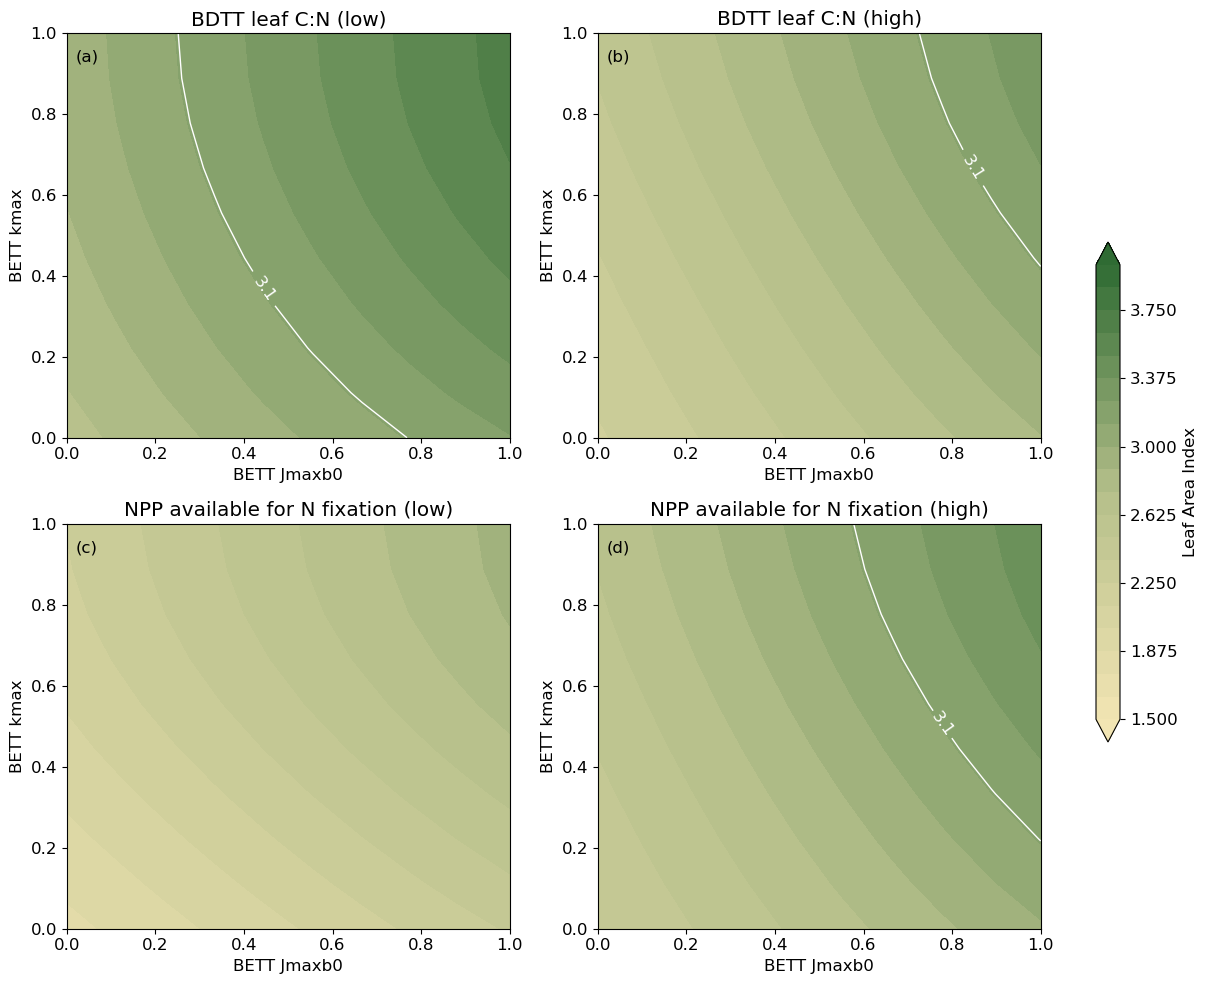

In [12]:
fig = plt.figure(figsize=(12,10))
plt.rcParams.update({'font.size': 12})

obs_lai = obs.LAI_mean.values[b]

ax1 = plt.subplot(2,2,1)
vmin=1.5
vmax = 4
levels = np.linspace(vmin, vmax, 21)  
cf1 = ax1.contourf(v, v, Y1.T, levels=levels, cmap=cmap, extend='both')
#fig.colorbar(cf1, ax=ax1, label='Leaf Area Index')
cs = ax1.contour(v, v, Y1.T, levels=[3.13], colors='white', linewidths=1.0)
ax1.clabel(cs, inline=True, fontsize=12, fmt='%.1f')
plt.xlabel('BETT Jmaxb0')
plt.ylabel('BETT kmax')
ax1.set_title('BDTT leaf C:N (low)')
ax1.text(0.02, 0.96, '(a)', transform=ax1.transAxes, fontsize=12,
          color='k', va='top', ha='left')

plt.subplot(2,2,2)
plt.contourf(v, v, Y2.T, levels=levels, cmap=cmap, extend='both')
#plt.colorbar(label='Leaf Area Index')
cs = plt.contour(v, v, Y2.T, levels=[3.13], colors='white', linewidths=1.0)
plt.clabel(cs, inline=True, fontsize=12, fmt='%.1f')
plt.xlabel('BETT Jmaxb0')
plt.ylabel('BETT kmax')
plt.title('BDTT leaf C:N (high)')
plt.tight_layout()
plt.text(0.02, 0.96, '(b)', transform=plt.gca().transAxes, fontsize=12,
          color='k', va='top', ha='left')

plt.subplot(2,2,3)
plt.contourf(v, v, Y3.T, levels=levels, cmap=cmap, extend='both')
#plt.colorbar(label='Leaf Area Index')
cs = plt.contour(v, v, Y3.T, levels=[3.13], colors='white', linewidths=1.0)
plt.clabel(cs, inline=True, fontsize=12, fmt='%.1f')
plt.xlabel('BETT Jmaxb0')
plt.ylabel('BETT kmax')
plt.title('NPP available for N fixation (low)')
plt.text(0.02, 0.96, '(c)', transform=plt.gca().transAxes, fontsize=12,
          color='k', va='top', ha='left')

plt.subplot(2,2,4)
plt.contourf(v, v, Y4.T, levels=levels, cmap=cmap, extend='both')
#plt.colorbar(label='Leaf Area Index')
cs = plt.contour(v, v, Y4.T, levels=[3.13], colors='white', linewidths=1.0)
plt.clabel(cs, inline=True, fontsize=12, fmt='%.1f')
plt.xlabel('BETT Jmaxb0')
plt.ylabel('BETT kmax')
plt.title('NPP available for N fixation (high)')
plt.text(0.02, 0.96, '(d)', transform=plt.gca().transAxes, fontsize=12,
          color='k', va='top', ha='left')


fig.tight_layout(rect=[0, 0, 0.9, 1])
cbar_ax = fig.add_axes([0.92, 0.25, 0.02, 0.5])   # [left, bottom, width, height]
fig.colorbar(cf1, cax=cbar_ax, label='Leaf Area Index')

plt.savefig('../figs/figure6_response_surface.png',dpi=300, bbox_inches='tight')